In [1]:
import warnings

with warnings.catch_warnings():
    warnings.simplefilter(action="ignore", category=FutureWarning)

    import os, math
    from pathlib import Path
    import scanpy as sc
    import numpy as np
    import seaborn as sns
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    from tqdm import tqdm
    from scipy import stats
    from scipy.stats import pearsonr, spearmanr
    from scipy.sparse import issparse

    from scipy.stats import wilcoxon, rankdata
    from statsmodels.stats.multitest import multipletests
    from itertools import combinations

    pd.set_option("display.max_rows", 500)
    pd.set_option("display.max_columns", None)

os.chdir(".././")

In [2]:
obs = pd.read_csv("5.3_dw_obs_all_scores_and_bins.csv", index_col=0, engine="python")
obs.rename(columns={"sp_score": "sp", "sid_score": "sid"}, inplace=True)
print(obs.shape)
obs.sample(2)

(1253024, 27)


,GSE_id,GSM_id,Age,Tissue_global,cell_type_final,Age_bin,cell_type,n_expr_genes,sp,RecSID,sid,ds,fridman,cellage,senmayo,sp_centered_median,sid_centered_median,ds_centered_median,sp_is_sen_median_ct,sid_is_sen_median_ct,ds_is_sen_median_ct,sp_is_sen_median_gse,sid_is_sen_median_gse,ds_is_sen_median_gse,sp_is_sen_median_gsm,sid_is_sen_median_gsm,ds_is_sen_median_gsm
HCAHeart7757639_CACACCTTCAGCGACC-1,Heart_Nuclei,D3,58.0,Heart_Nuclei,Fibroblast,51.0,Fibroblasts,801.0,1.480099,SID3,0.285186,1.600269,0.084666,0.052599,0.050366,1.192512,-0.011543,1.146450,True,False,True,True,False,True,True,False,True
HCAHeart7844004_GCTTCCAGTAACGACG-1,Heart_Cell,D6,68.0,Heart_Cell,Endothelial cell,61.0,Endothelial cells,549.0,0.656566,SID3,0.456689,-1.538579,0.137060,0.050282,0.071484,-0.624579,-0.341782,-0.826082,False,False,False,False,False,False,False,False,False


In [3]:
sen_sigs = ["fridman", "senmayo", "cellage"]
methods = ["sp", "ds", "sid"]

In [4]:
cols_to_drop = obs.filter(regex="_is_sen_median_ct$|_is_sen_median_gsm$").columns
obs.drop(columns=cols_to_drop, inplace=True)

In [5]:
"""assign Sc/NSc groups (NSc = ~Sc)"""

for m in methods:
    obs_filt = obs[m]
    obs[f"{m}_sen_group"] = pd.NA
    # valid = obs[m].notna()
    # obs_filt = obs.loc[valid].copy()

    mask_sc = obs[f"{m}_is_sen_median_gse"] == True
    mask_nsc = obs[f"{m}_is_sen_median_gse"] == False
    obs.loc[mask_sc, f"{m}_sen_group"] = "Sc"
    obs.loc[mask_nsc, f"{m}_sen_group"] = "NSc"

In [6]:
obs.columns

Index(['GSE_id', 'GSM_id', 'Age', 'Tissue_global', 'cell_type_final',
       'Age_bin', 'cell_type', 'n_expr_genes', 'sp', 'RecSID', 'sid', 'ds',
       'fridman', 'cellage', 'senmayo', 'sp_centered_median',
       'sid_centered_median', 'ds_centered_median', 'sp_is_sen_median_gse',
       'sid_is_sen_median_gse', 'ds_is_sen_median_gse', 'sp_sen_group',
       'ds_sen_group', 'sid_sen_group'],
      dtype='object')

#### Continious scores: pairwise Pearson + Spearman

In [7]:
group_cols = ["GSM_id", "Tissue_global", "cell_type"]

corr_cols = group_cols + methods + [f"{m}_sen_group" for m in methods]

In [8]:
group_availability = obs.groupby(
    ["GSM_id", "Tissue_global", "cell_type"], observed=True
)[methods].agg(lambda x: x.notna().any())

group_availability["all_three"] = group_availability.all(axis=1)

group_availability = group_availability.reset_index()

In [9]:
group_availability.head()

,GSM_id,Tissue_global,cell_type,sp,ds,sid,all_three
0,A61,Heart_Nuclei,Atrial cardiomyocytes,True,True,True,True
1,A61,Heart_Nuclei,CD4 T cells,True,True,True,True
2,A61,Heart_Nuclei,CD8 T cells,True,True,True,True
3,A61,Heart_Nuclei,Endothelial cells,True,True,True,True
4,A61,Heart_Nuclei,Fibroblasts,True,True,True,True


In [10]:
obs_corr = obs[corr_cols].copy()

In [13]:
def calculate_score_concordance(
    obs, methods, group_cols, analysis="primary", min_cells=20
):
    """Парные корреляции методов внутри биологических групп.

    analysis='primary':   Достаточно наличия данных по текущей паре методов.
    analysis='secondary': Требует наличия данных по всем трем методам в группе.
    """
    if analysis not in ["primary", "secondary"]:
        raise ValueError("analysis must be 'primary' or 'secondary'")

    results = []

    # 1. Заранее находим группы, где есть абсолютно все методы (нужно для secondary)
    all_methods_available = (
        obs.groupby(group_cols, observed=True)[methods]
        .agg(lambda x: x.notna().any())
        .all(axis=1)
    )
    strict_groups = all_methods_available[all_methods_available].index

    # 2. Итерируемся по парам методов
    for m1, m2 in combinations(methods, 2):
        # Выбираем валидные группы в зависимости от режима анализа
        if analysis == "secondary":
            valid_groups = strict_groups
        else:  # primary
            availability = obs.groupby(group_cols, observed=True)[[m1, m2]].agg(
                lambda x: x.notna().any()
            )
            valid_groups = availability[availability.all(axis=1)].index

        # Фильтруем датафрейм по выбранным группам и убираем NaNs
        pair_df = obs[group_cols + [m1, m2]].copy()
        pair_df = pair_df[pair_df.set_index(group_cols).index.isin(valid_groups)]
        pair_df = pair_df.dropna(subset=[m1, m2])

        # Считаем корреляции внутри каждой группы
        for group_key, df_g in pair_df.groupby(group_cols, observed=True):
            if len(df_g) < min_cells:
                continue

            x = df_g[m1].to_numpy()
            y = df_g[m2].to_numpy()

            # Pearson r
            p_r, p_p = (
                pearsonr(x, y) if np.std(x) > 0 and np.std(y) > 0 else (np.nan, np.nan)
            )

            # Spearman rho
            s_r, s_p = (
                spearmanr(x, y)
                if len(np.unique(x)) > 1 and len(np.unique(y)) > 1
                else (np.nan, np.nan)
            )

            # Собираем строку результатов динамически по group_cols
            res_row = {
                "analysis": analysis,
                "method_1": m1,
                "method_2": m2,
                "n_cells": len(df_g),
                "pearson_r": p_r,
                "pearson_p": p_p,
                "spearman_rho": s_r,
                "spearman_p": s_p,
            }

            # Безопасная запись ключей группы независимо от их количества
            if len(group_cols) == 1:
                res_row[group_cols[0]] = group_key
            else:
                for col_name, col_val in zip(group_cols, group_key):
                    res_row[col_name] = col_val

            results.append(res_row)

    return pd.DataFrame(results)


In [14]:
corr_primary = calculate_score_concordance(
    obs,
    methods,
    group_cols,
    analysis="primary",
)

In [18]:
"""агрегация корреляций - насколько стабильно 
методы согласуются между donor × tissue × cell type"""

corr_summary = (
    corr_primary.groupby(["method_1", "method_2"], observed=True)
    .agg(
        n_groups=("spearman_rho", "count"),
        median_spearman=("spearman_rho", "median"),
        q25_spearman=("spearman_rho", lambda x: x.quantile(0.25)),
        q75_spearman=("spearman_rho", lambda x: x.quantile(0.75)),
        median_pearson=("pearson_r", "median"),
        q25_pearson=("pearson_r", lambda x: x.quantile(0.25)),
        q75_pearson=("pearson_r", lambda x: x.quantile(0.75)),
        frac_positive_spearman=("spearman_rho", lambda x: (x > 0).mean()),
    )
    .reset_index()
)

corr_summary

,method_1,method_2,n_groups,median_spearman,q25_spearman,q75_spearman,median_pearson,q25_pearson,q75_pearson,frac_positive_spearman
0,ds,sid,1126,0.001822,-0.054232,0.054476,0.001128,-0.051054,0.056127,0.512433
1,sp,ds,988,0.040544,-0.030549,0.119161,0.039565,-0.030408,0.105881,0.655870
2,sp,sid,988,0.000477,-0.054623,0.057164,-0.005664,-0.066094,0.050080,0.505061


In [25]:
import pandas as pd
from statsmodels.stats.diagnostic import lilliefors

methods = ["sp", "ds", "sid"]
results = []

# Группируем по тканям и типам клеток
for name, group_df in obs.groupby(["Tissue_global", "cell_type"], observed=True):
    tissue, cell_type = name

    group_res = {"Tissue": tissue, "Cell_Type": cell_type}

    for method in methods:
        clean_values = group_df[method].dropna()
        n_samples = len(clean_values)

        # Для Лиллиефорса желательно иметь хотя бы 4-5 точек
        if n_samples < 5:
            group_res[method] = "Мало данных (<5)"
        else:
            if clean_values.nunique() == 1:
                group_res[method] = "Не нормально"
                continue

            # Проводим тест Лиллиефорса
            # pdist='norm' указывает, что мы проверяем именно нормальное распределение
            stat, p_value = lilliefors(clean_values, dist="norm")

            group_res[method] = "Нормально" if p_value > 0.05 else "Не нормально"

    results.append(group_res)

# Собираем и агрегируем результаты
report_df = pd.DataFrame(results)

summary_data = {}
for method in methods:
    counts = report_df[method].value_counts()
    summary_data[method] = {
        "Нормально": counts.get("Нормально", 0),
        "Не нормально": counts.get("Не нормально", 0),
        "Мало данных": counts.get("Мало данных (<5)", 0),
    }

summary_df = pd.DataFrame(summary_data)

print("=" * 70)
print("ТЕСТ НА НОРМАЛЬНОСТЬ: Критерий Колмогорова-Смирнова в модификации Лиллиефорса")
print("=" * 70)
print("\nСводная статистика по количеству групп:")
print(summary_df)
print("=" * 70)


ТЕСТ НА НОРМАЛЬНОСТЬ: Критерий Колмогорова-Смирнова в модификации Лиллиефорса

Сводная статистика по количеству групп:
              sp  ds  sid
Нормально      0   0    0
Не нормально  57  72   72
Мало данных   15   0    0








In [26]:
# ============================================================
# CORRELATION HEATMAP
# X-axis : Tissue_global | cell_type
# Y-axis : method pairs
# ============================================================


def format_corr(value):
    if pd.isna(value):
        return ""
    return f"{value:.2f}".replace("-0.", "-.").replace("0.", ".")


method_pairs = [
    ("sp", "ds"),
    ("sp", "sid"),
    ("ds", "sid"),
]
pair_labels = [
    "sp – ds",
    "sp – sid",
    "ds – sid",
]


for VALUE_COL in ["spearman_rho", "pearson_r"]:
    # 1. Corresponding p-value column
    if VALUE_COL == "spearman_rho":
        P_COL = "spearman_p"
    else:
        P_COL = "pearson_p"

    # 2. Median correlation and p-value
    #    for each tissue × cell type × method pair
    summary = (
        corr_primary.groupby(
            [
                "Tissue_global",
                "cell_type",
                "method_1",
                "method_2",
            ],
            observed=True,
        )[[VALUE_COL, P_COL]]
        .median()
        .reset_index()
    )

    # 3. Assign method-pair labels
    pair_to_label = {pair: label for pair, label in zip(method_pairs, pair_labels)}
    summary["method_pair"] = [
        pair_to_label.get((m1, m2), pair_to_label.get((m2, m1)))
        for m1, m2 in zip(
            summary["method_1"],
            summary["method_2"],
        )
    ]
    summary = summary.dropna(subset=["method_pair"])

    # 4. Create X-axis labels
    summary["group"] = (
        summary["Tissue_global"].astype(str) + " | " + summary["cell_type"].astype(str)
    )

    # 5. X-axis order
    group_order = (
        summary[
            [
                "Tissue_global",
                "cell_type",
                "group",
            ]
        ]
        .drop_duplicates()
        .sort_values(["Tissue_global", "cell_type"])["group"]
        .tolist()
    )

    # 6. Create correlation matrix
    #    rows = method pairs
    #    columns = tissue × cell type
    heatmap_df = summary.pivot(
        index="method_pair",
        columns="group",
        values=VALUE_COL,
    ).reindex(
        index=pair_labels,
        columns=group_order,
    )

    # 7. Create corresponding p-value matrix
    pvalue_df = summary.pivot(
        index="method_pair",
        columns="group",
        values=P_COL,
    ).reindex(
        index=pair_labels,
        columns=group_order,
    )

    # 8. Figure
    fig_width = max(10, len(heatmap_df.columns) * 0.6)
    fig, ax = plt.subplots(
        figsize=(fig_width, 8),
        dpi=300,
    )

    # 9. Heatmap
    sns.heatmap(
        heatmap_df,
        annot=False,
        fmt=" .2f",
        vmin=-1,
        vmax=1,
        center=0,
        cmap="BrBG_r",
        linewidths=0.5,
        linecolor="white",
        cbar=True,
        cbar_kws={
            "shrink": 1.3,
            "aspect": 5,
            "pad": 0.025,
        },
        annot_kws={
            "fontsize": 13,
        },
        ax=ax,
    )

    # Add annotations
    # Significant values are bold
    for row_idx in range(heatmap_df.shape[0]):
        for col_idx in range(heatmap_df.shape[1]):
            value = heatmap_df.iloc[row_idx, col_idx]
            p_value = pvalue_df.iloc[row_idx, col_idx]

            if pd.isna(value):
                continue

            ax.text(
                col_idx + 0.5,
                row_idx + 0.5,
                format_corr(value),
                ha="center",
                va="center",
                fontweight=(
                    "bold" if pd.notna(p_value) and p_value < 0.05 else "normal"
                ),
                fontsize=(14 if pd.notna(p_value) and p_value < 0.05 else 13),
                # color='white'
            )

    # 11. Axis labels
    ax.set_xlabel(
        "Tissue | cell type",
        fontsize=21,
        fontweight="normal",
        labelpad=10,
    )
    ax.set_ylabel(
        "Method pair",
        fontsize=21,
        fontweight="normal",
        labelpad=15,
    )
    # 12. X-axis labels
    ax.tick_params(
        axis="x",
        bottom=True,
        top=False,
        labelbottom=True,
        labeltop=False,
        length=8,
        width=1.5,
        pad=3,
    )

    # 13. Y-axis labels
    ax.tick_params(
        axis="y",
        left=True,
        right=False,
        length=0,
        pad=8,
    )

    # X tick labels
    for label in ax.get_xticklabels():
        label.set_fontsize(18)
        label.set_fontweight("semibold")
        label.set_rotation(45)
        label.set_ha("right")
    # Y tick labels
    for label in ax.get_yticklabels():
        label.set_fontsize(19)
        label.set_fontweight("semibold")
        label.set_rotation(0)

    # 14. Colorbar
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(
        labelsize=12,
        length=3,
    )

    if VALUE_COL == "spearman_rho":
        cbar_label = "Spearman ρ"
    else:
        cbar_label = "Pearson r"

    cbar.set_label(
        cbar_label,
        fontsize=17,
        fontweight="normal",
        labelpad=10,
    )

    # 15. Figure title
    if VALUE_COL == "spearman_rho":
        title = "Spearman correlation"
    else:
        title = "Pearson correlation"

    ax.set_title(
        title,
        fontsize=19,
        fontweight="normal",
        pad=25,
    )

    plt.tight_layout()
    plt.show()

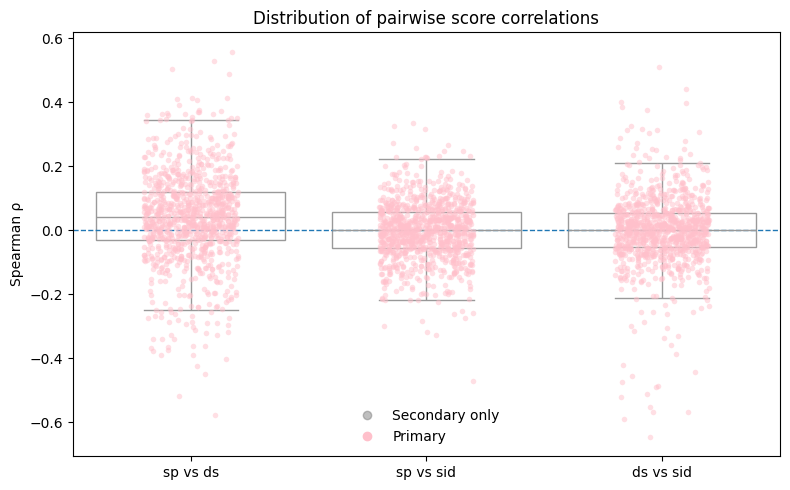

'по пирсону примерно то же самое'

In [29]:
"""Распределение Spearman ρ по всем комбинациям методов.
Цветом обозначен тип анализа: primary / secondary."""

# Все доступные pairwise группы
plot_df = corr_secondary.copy()

# Уникальный идентификатор biological group + пары методов
group_id_cols = ["method_1", "method_2", "GSM_id", "Tissue_global", "cell_type"]

# Определяем, какие группы входят в primary
primary_groups = corr_primary[group_id_cols].drop_duplicates().assign(is_primary=True)

# Присоединяем информацию о принадлежности к primary
plot_df = plot_df.merge(primary_groups, on=group_id_cols, how="left")

plot_df["analysis"] = np.where(
    plot_df["is_primary"].fillna(False), "primary", "secondary only"
)

plot_df["method_pair"] = plot_df["method_1"] + " vs " + plot_df["method_2"]


plt.figure(figsize=(8, 5))

# Общее распределение
sns.boxplot(data=plot_df, x="method_pair", y="spearman_rho", color="white", fliersize=0)

# Все secondary-only точки
secondary_only = plot_df[plot_df["analysis"] == "secondary only"]

sns.stripplot(
    data=secondary_only,
    x="method_pair",
    y="spearman_rho",
    jitter=0.2,
    alpha=0.55,
    size=4,
    color="gray",
)

# Primary points поверх них
primary = plot_df[plot_df["analysis"] == "primary"]

sns.stripplot(
    data=primary,
    x="method_pair",
    y="spearman_rho",
    jitter=0.2,
    alpha=0.5,
    size=4,
    color="pink",
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.ylabel("Spearman ρ")
plt.xlabel("")
plt.title("Distribution of pairwise score correlations")

plt.legend(
    handles=[
        plt.Line2D(
            [0],
            [0],
            marker="o",
            linestyle="",
            markerfacecolor="gray",
            markeredgecolor="gray",
            alpha=0.5,
            label="Secondary only",
        ),
        plt.Line2D(
            [0],
            [0],
            marker="o",
            linestyle="",
            markerfacecolor="pink",
            markeredgecolor="pink",
            label="Primary",
        ),
    ],
    frameon=False,
)

plt.tight_layout()
plt.show()

"по пирсону примерно то же самое"

#### binary concordance: Sc/NSc

**3. Мера согласия (cohen's kappa)**

Отвечает на вопрос *насколько хорошо два метода согласуют бинарную классификацию **с поправкой на случайное совпадение**?* Ибо % совпадения/accuracy/etc мб искуственно завышен при доминировании одного из классов (в нашем случае это NSc)

In [30]:
from sklearn.metrics import cohen_kappa_score

binary_cols = [f"{m}_sen_group" for m in methods]

# Availability of binary labels
availability = obs.groupby(group_cols, observed=True)[binary_cols].agg(
    lambda x: x.notna().any()
)
# Primary = all three methods available
availability["is_primary"] = availability.all(axis=1)
availability = availability.reset_index()

binary_results = []

for m1, m2 in combinations(methods, 2):
    group1 = f"{m1}_sen_group"
    group2 = f"{m2}_sen_group"

    # Groups where BOTH methods are available
    pair_availability = availability[availability[[group1, group2]].all(axis=1)].copy()

    pair_availability = pair_availability[group_cols + ["is_primary"]]

    # Keep only relevant columns
    pair_df = obs[group_cols + [group1, group2]].merge(
        pair_availability, on=group_cols, how="inner"
    )

    # Remove cells without both labels
    pair_df = pair_df.dropna(subset=[group1, group2])

    # Calculate concordance within each group
    for group_key, df_g in pair_df.groupby(group_cols, observed=True):
        if len(df_g) < 20:  # min_cells
            continue

        a = df_g[group1].to_numpy()
        b = df_g[group2].to_numpy()

        # Convert labels to binary
        # Sc = 1, NSc = 0
        a_bin = (a == "Sc").astype(int)
        b_bin = (b == "Sc").astype(int)

        TP = np.sum((a_bin == 1) & (b_bin == 1))
        FP = np.sum((a_bin == 1) & (b_bin == 0))
        FN = np.sum((a_bin == 0) & (b_bin == 1))
        TN = np.sum((a_bin == 0) & (b_bin == 0))

        # Jaccard
        union = TP + FP + FN

        jaccard = TP / union if union > 0 else np.nan

        # Conditional overlaps
        # A among B
        overlap_a_given_b = TP / (TP + FN) if (TP + FN) > 0 else np.nan

        # B among A
        overlap_b_given_a = TP / (TP + FP) if (TP + FP) > 0 else np.nan

        # Overall agreement
        agreement = (TP + TN) / len(df_g)

        # Cohen's kappa
        if len(np.unique(a_bin)) > 1 and len(np.unique(b_bin)) > 1:
            kappa = cohen_kappa_score(a_bin, b_bin)
        else:
            kappa = np.nan

        binary_results.append(
            {
                "method_1": m1,
                "method_2": m2,
                "GSM_id": group_key[0],
                "Tissue_global": group_key[1],
                "cell_type": group_key[2],
                "n_cells": len(df_g),
                "n_Sc_m1": int(a_bin.sum()),
                "n_Sc_m2": int(b_bin.sum()),
                "TP": TP,
                "FP": FP,
                "FN": FN,
                "TN": TN,
                "sc_fraction_m1": a_bin.mean(),
                "sc_fraction_m2": b_bin.mean(),
                "jaccard": jaccard,
                "overlap_m1_given_m2": overlap_a_given_b,
                "overlap_m2_given_m1": overlap_b_given_a,
                "agreement": agreement,
                "cohen_kappa": kappa,
                "is_primary": bool(df_g["is_primary"].iloc[0]),
            }
        )

binary_df = pd.DataFrame(binary_results)

In [33]:
"""aggreration"""
binary_summary = (
    binary_df[binary_df.is_primary]
    .groupby(["method_1", "method_2"], observed=True)
    .agg(
        n_groups=("jaccard", "count"),
        median_jaccard=("jaccard", "median"),
        q25_jaccard=("jaccard", lambda x: x.quantile(0.25)),
        q75_jaccard=("jaccard", lambda x: x.quantile(0.75)),
        median_overlap_m1_given_m2=("overlap_m1_given_m2", "median"),
        median_overlap_m2_given_m1=("overlap_m2_given_m1", "median"),
        median_agreement=("agreement", "median"),
        median_kappa=("cohen_kappa", "median"),
        q25_kappa=("cohen_kappa", lambda x: x.quantile(0.25)),
        q75_kappa=("cohen_kappa", lambda x: x.quantile(0.75)),
    )
    .reset_index()
)

binary_summary

,method_1,method_2,n_groups,median_jaccard,q25_jaccard,q75_jaccard,median_overlap_m1_given_m2,median_overlap_m2_given_m1,median_agreement,median_kappa,q25_kappa,q75_kappa
0,ds,sid,987,0.063415,0.017170,0.108724,0.113119,0.184984,0.697210,0.001110,-0.027942,0.035116
1,sp,ds,987,0.056180,0.021739,0.102360,0.134848,0.114286,0.759507,0.006532,-0.030557,0.050006
2,sp,sid,988,0.076923,0.035083,0.119888,0.143285,0.193564,0.703203,-0.001069,-0.035894,0.034600


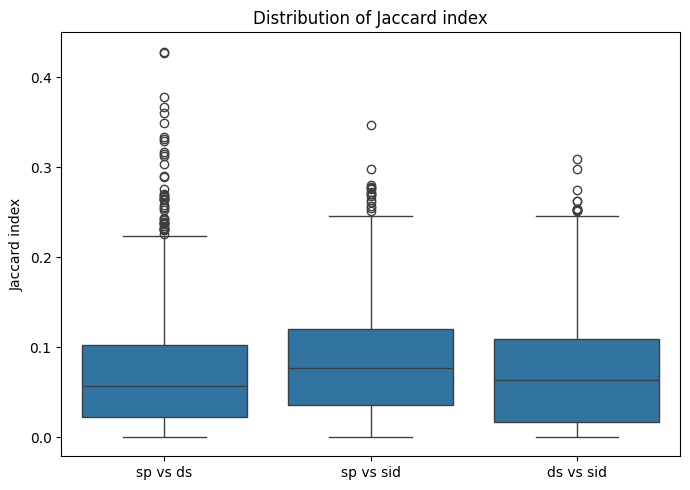

In [35]:
binary_df["method_pair"] = binary_df["method_1"] + " vs " + binary_df["method_2"]

plt.figure(figsize=(7, 5))

sns.boxplot(data=binary_df[binary_df.is_primary], x="method_pair", y="jaccard")

plt.ylabel("Jaccard index")
plt.xlabel("")
plt.title("Distribution of Jaccard index")
plt.tight_layout()
plt.show()

In [36]:
"""conditional overlap"""

conditional_matrix = pd.DataFrame(np.nan, index=methods, columns=methods)

for _, row in binary_df[binary_df.is_primary].iterrows():
    m1 = row["method_1"]
    m2 = row["method_2"]

    conditional_matrix.loc[m1, m2] = row["overlap_m1_given_m2"]

    conditional_matrix.loc[m2, m1] = row["overlap_m2_given_m1"]

matrix_values = conditional_matrix.to_numpy(copy=True)
np.fill_diagonal(matrix_values, 1)
conditional_matrix.iloc[:, :] = matrix_values

In [37]:
"""
строка = метод, который мы проверяем
столбец = reference method
"""
conditional_matrix

,sp,ds,sid
sp,1.000000,0.053191,0.165637
ds,0.029470,1.000000,0.054388
sid,0.263261,0.156028,1.000000


In [54]:
spearman_vmin = -0.5
spearman_vmax = 0.6
jaccard_vmin = 0
jaccard_vmax = 0.3
kappa_vmin = -0.35
kappa_vmax = 0.35

In [58]:
corr_df.to_csv(".././6.2.2_corr_df_dw.csv")
binary_df.to_csv(".././6.2.2_binary_df_dw.csv")

In [57]:
# INTEGRATED HEATMAP
#
# Top    : Spearman correlation
# Middle : Jaccard index
# Bottom : Cohen's kappa
#
# X-axis : Tissue_global | cell_type
# Y-axis : method pairs
# ============================================================

method_pairs = [("sp", "ds"), ("sp", "sid"), ("ds", "sid")]
pair_labels = ["sp – ds", "sp – sid", "ds – sid"]

# 1. Prepare BINARY data
pair_to_label = {pair: label for pair, label in zip(method_pairs, pair_labels)}

binary_df["method_pair"] = [
    pair_to_label.get((m1, m2), pair_to_label.get((m2, m1)))
    for m1, m2 in zip(binary_df["method_1"], binary_df["method_2"])
]
binary_df = binary_df.dropna(subset=["method_pair"])
binary_df["group"] = (
    binary_df["Tissue_global"].astype(str) + " | " + binary_df["cell_type"].astype(str)
)


# 2. Prepare CORRELATION data
corr_df = corr_primary.copy()
corr_df["method_pair"] = [
    pair_to_label.get((m1, m2), pair_to_label.get((m2, m1)))
    for m1, m2 in zip(corr_df["method_1"], corr_df["method_2"])
]
corr_df = corr_df.dropna(subset=["method_pair"])
corr_df["group"] = (
    corr_df["Tissue_global"].astype(str) + " | " + corr_df["cell_type"].astype(str)
)


# 3. Common X-axis order
# Use all groups present in the three analyses
group_order = (
    pd.concat(
        [
            binary_df[["Tissue_global", "cell_type", "group"]],
            corr_df[["Tissue_global", "cell_type", "group"]],
        ],
        ignore_index=True,
    )
    .drop_duplicates()
    .sort_values(["Tissue_global", "cell_type"])["group"]
    .tolist()
)

# 4. Aggregate BINARY metrics across GSM_id
binary_summary = (
    binary_df.groupby(
        ["method_pair", "Tissue_global", "cell_type"],
        observed=True,
    )[["jaccard", "cohen_kappa"]]
    .median()
    .reset_index()
)
binary_summary["group"] = (
    binary_summary["Tissue_global"].astype(str)
    + " | "
    + binary_summary["cell_type"].astype(str)
)

# 5. Aggregate SPEARMAN across GSM_id
spearman_summary = (
    corr_df.groupby(
        ["method_pair", "Tissue_global", "cell_type"],
        observed=True,
    )[["spearman_rho", "spearman_p"]]
    .median()
    .reset_index()
)
spearman_summary["group"] = (
    spearman_summary["Tissue_global"].astype(str)
    + " | "
    + spearman_summary["cell_type"].astype(str)
)

# 6. Create matrices
spearman_df = spearman_summary.pivot(
    index="method_pair", columns="group", values="spearman_rho"
).reindex(index=pair_labels, columns=group_order)
spearman_p_df = spearman_summary.pivot(
    index="method_pair", columns="group", values="spearman_p"
).reindex(index=pair_labels, columns=group_order)
jaccard_df = binary_summary.pivot(
    index="method_pair", columns="group", values="jaccard"
).reindex(index=pair_labels, columns=group_order)
kappa_df = binary_summary.pivot(
    index="method_pair", columns="group", values="cohen_kappa"
).reindex(index=pair_labels, columns=group_order)

# 7. Metric-specific color ranges
# spearman_vmin = spearman_df.min().min()
# spearman_vmax = spearman_df.max().max()
# jaccard_vmin = jaccard_df.min().min()
# jaccard_vmax = jaccard_df.max().max()
# kappa_vmin = kappa_df.min().min()
# kappa_vmax = kappa_df.max().max()


# 8. Helper for missing values
def add_missing_marks(ax, data):
    for row_idx in range(data.shape[0]):
        for col_idx in range(data.shape[1]):
            value = data.iloc[row_idx, col_idx]

            if pd.isna(value):
                ax.text(
                    col_idx + 0.5,
                    row_idx + 0.5,
                    "–",
                    ha="center",
                    va="center",
                    fontsize=35,
                    fontweight="normal",
                )


# 9. Figure
fig_width = max(10, len(group_order) * 0.9)
fig = plt.figure(figsize=(fig_width, 18), dpi=300)

gs = fig.add_gridspec(
    nrows=3,
    ncols=2,
    width_ratios=[0.01, 1],
    height_ratios=[1, 1, 1],
    wspace=0.09,
    hspace=0.12,
)

# Colorbar axes
cbar_axes = [
    fig.add_subplot(gs[0, 0]),
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[2, 0]),
]

# Heatmap axes
ax0 = fig.add_subplot(gs[0, 1])
ax1 = fig.add_subplot(gs[1, 1], sharex=ax0)
ax2 = fig.add_subplot(gs[2, 1], sharex=ax0)

axes = [ax0, ax1, ax2]

# 10. SPEARMAN
ax = axes[0]
sns.heatmap(
    spearman_df,
    # annot=True,
    # fmt='.2f',
    annot=False,
    vmin=spearman_vmin,
    vmax=spearman_vmax,
    cmap="BrBG_r",
    linewidths=0.5,
    linecolor="white",
    cbar=True,
    cbar_kws={
        "shrink": 0.9,
        "aspect": 10,
        "pad": 0.01,
    },
    ax=ax,
    cbar_ax=cbar_axes[0],
)
# Missing values
add_missing_marks(
    ax,
    spearman_df,
)

# Significant correlations
for row_idx in range(spearman_df.shape[0]):
    for col_idx in range(spearman_df.shape[1]):
        value = spearman_df.iloc[row_idx, col_idx]
        p_value = spearman_p_df.iloc[row_idx, col_idx]

        if pd.notna(value) and pd.notna(p_value) and p_value < 0.05:
            ax.text(
                col_idx + 0.5,
                row_idx + 0.5,
                "∗",
                ha="center",
                va="center",
                fontsize=40,
                fontweight="bold",
            )

# Colorbar
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(
    labelsize=32,
    length=3,
)
cbar.set_label(
    "Spearman ρ  ",
    fontsize=50,
    fontweight="semibold",
    labelpad=12,
)

# 11. JACCARD
ax = axes[1]
sns.heatmap(
    jaccard_df,
    # annot=True,
    # fmt='.2f',
    annot=False,
    vmin=jaccard_vmin,
    vmax=jaccard_vmax,
    cmap="YlGnBu",
    linewidths=0.5,
    linecolor="white",
    cbar=True,
    cbar_kws={
        "shrink": 0.9,
        "aspect": 10,
        "pad": 0.025,
    },
    ax=ax,
    cbar_ax=cbar_axes[1],
)
# Missing values
add_missing_marks(
    ax,
    jaccard_df,
)

# Colorbar
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(
    labelsize=32,
    length=3,
)
cbar.set_label(
    "Jaccard",
    fontsize=50,
    fontweight="semibold",
    labelpad=12,
)

# 12. COHEN'S KAPPA
ax = axes[2]
sns.heatmap(
    kappa_df,
    # annot=True,
    # fmt='.2f',
    annot=False,
    vmin=kappa_vmin,
    vmax=kappa_vmax,
    cmap="PuRd",
    linewidths=0.5,
    linecolor="white",
    cbar=True,
    cbar_kws={
        "shrink": 0.9,
        "aspect": 10,
        "pad": 0.025,
    },
    ax=ax,
    cbar_ax=cbar_axes[2],
)
# Missing values
add_missing_marks(
    ax,
    kappa_df,
)


# Colorbar
from matplotlib.ticker import LinearLocator
from matplotlib.ticker import FormatStrFormatter

cbar = ax.collections[0].colorbar
# Устанавливаем ровно 5 делений на всю шкалу колорбара
# cbar.ax.yaxis.set_major_locator(LinearLocator(numticks=4))
# cbar.ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))

cbar.ax.tick_params(
    labelsize=32,
    length=3,
)
cbar.set_label(
    "Cohen's κ",
    fontsize=50,
    fontweight="semibold",
    labelpad=12,
)

# ============================================================
# X-axis labels
# Верхние панели: полностью скрываем X-axis labels и ticks
for ax in axes[:2]:
    ax.tick_params(
        axis="x",
        which="both",
        bottom=False,
        top=False,
        labelbottom=False,
        labeltop=False,
    )
    ax.set_xlabel("")

# Нижняя панель: показываем только здесь
axes[2].set_xticklabels(
    group_order,
    fontsize=50,
    fontweight="semibold",
    rotation=90,
    ha="center",
)
axes[2].tick_params(
    axis="x",
    which="both",
    bottom=True,
    top=False,
    labelbottom=True,
    labeltop=False,
    length=10,
    width=3,
)
axes[2].set_xlabel("Tissue | cell type", fontsize=68, fontweight="normal", labelpad=15)

# Y-axis
for ax in axes:
    ax.tick_params(
        axis="y",
        left=False,
        right=True,
        labelleft=False,
        labelright=True,
        length=0,
        width=0.8,
        pad=8,
    )
    for label in ax.get_yticklabels():
        label.set_fontsize(57)
        label.set_fontweight("semibold")
        label.set_rotation(0)
    ax.set_ylabel("")

    cbar = ax.collections[0].colorbar
    cbar.ax.yaxis.set_ticks_position("right")
    cbar.ax.yaxis.set_label_position("left")


fig.text(
    0.98,
    0.5,
    "\nMethods pair",
    rotation=90,
    va="center",
    ha="center",
    fontsize=68,
    fontweight="normal",
)
# 14. Layout
plt.subplots_adjust(left=0.12, right=0.92, bottom=0.20, top=0.94, hspace=0.01)

plt.show()

# чтобы убрать аннотацию в хитмапах - пройтись по каждому, annot=False
# и в функции отрисовки стат.значимых звездочек убрать перенос строки

In [50]:
print(spearman_df.min().min())
print(spearman_df.max().max())
print(jaccard_df.min().min())
print(jaccard_df.max().max())
print(kappa_df.min().min())
print(kappa_df.max().max())

-0.49988068959694526
0.2884824706503435
0.0
0.2698412698412698
-0.3120801548445862
0.32089906121190215





In [49]:
# ============================================================
# Conditional Sc Overlap heatmap (INVERTED)
# ============================================================
methods = ["sp", "ds", "sid"]

column_structure = [
    ("sp", "ds"),
    ("sp", "sid"),
    ("ds", "sp"),
    ("ds", "sid"),
    ("sid", "sp"),
    ("sid", "ds"),
]

# Базовый шрифт, от которого масштабируются все элементы (уже +4 к исходным минимумам)
base_size = 21

# 3. Group = Tissue | cell type
binary_df["group"] = (
    binary_df["Tissue_global"].astype(str) + " | " + binary_df["cell_type"].astype(str)
)

# 4. Row order
group_info = (
    binary_df[["Tissue_global", "cell_type", "group"]]
    .drop_duplicates()
    .sort_values(["Tissue_global", "cell_type"])
)
group_order = group_info["group"].tolist()

# 5. Median conditional overlap across GSM_id
summary = (
    binary_df.groupby(
        ["Tissue_global", "cell_type", "method_1", "method_2"], observed=True
    )[["overlap_m1_given_m2", "overlap_m2_given_m1"]]
    .median()
    .reset_index()
)

# 6. Create matrix
conditional_matrix = pd.DataFrame(
    np.nan,
    index=group_order,
    columns=pd.MultiIndex.from_tuples(
        column_structure, names=["Tested method", "Reference method"]
    ),
)

# 7. Fill matrix
for _, row in summary.iterrows():
    group = str(row["Tissue_global"]) + " | " + str(row["cell_type"])
    m1 = row["method_1"]
    m2 = row["method_2"]

    if (m1, m2) in column_structure:
        conditional_matrix.loc[group, (m1, m2)] = row["overlap_m1_given_m2"]
    if (m2, m1) in column_structure:
        conditional_matrix.loc[group, (m2, m1)] = row["overlap_m2_given_m1"]

# !!! ИНВЕРСИЯ МАТРИЦЫ !!!
conditional_matrix_t = conditional_matrix.T

# 8. Color normalization
conditional_vmin = np.nanmin(conditional_matrix_t.values)
conditional_vmax = np.nanmax(conditional_matrix_t.values)

# 9. Figure
fig_width = max(12, len(group_order) * 0.72)
fig, ax = plt.subplots(figsize=(fig_width, 9), dpi=300)

# 10. Heatmap (annot_kws изменён динамически)
sns.heatmap(
    conditional_matrix_t,
    ax=ax,
    cmap="GnBu",
    vmin=conditional_vmin,
    vmax=conditional_vmax,
    annot=True,
    fmt=".2f",
    annot_kws={"size": base_size - 3},  # Было 16 (12 + 4)
    # annot=False,
    linewidths=0.5,
    linecolor="white",
    cbar=True,
    cbar_kws={"shrink": 0.9, "aspect": 12, "pad": 0.078},
)

# 11. Remove automatic axis labels
ax.set_xlabel(
    "Tissue | cell type", fontsize=base_size + 13, labelpad=-20
)  # Было 34 (30 + 4)
ax.set_ylabel("")

# 12. X-axis
ax.tick_params(
    axis="x",
    bottom=True,
    top=False,
    labelbottom=True,
    labeltop=False,
    length=4,
    width=0.8,
)

for label in ax.get_xticklabels():
    label.set_fontsize(base_size + 3)  # Было 22 (18 + 4)
    label.set_fontweight("semibold")
    label.set_rotation(45)
    label.set_horizontalalignment("right")
    label.set_rotation_mode("anchor")

# 13. Y-axis
ax.tick_params(
    axis="y",
    left=False,
    right=False,
    labelleft=False,
    labelright=False,
)

# 14. Tested method подписи слева
tested_groups = {"sp": (0, 2), "ds": (2, 4), "sid": (4, 6)}

for tested, (start, end) in tested_groups.items():
    center = (start + end) / 2
    ax.text(
        -0.38,
        center,
        tested,
        ha="right",
        va="center",
        fontsize=base_size + 9,  # Было 30 (26 + 4)
        fontweight="semibold",
        clip_on=False,
    )

# 15. Заголовок "Tested method" слева
ax.text(
    -2.9,
    conditional_matrix_t.shape[0] / 2,
    "Tested method",
    ha="right",
    va="center",
    fontsize=base_size + 13,  # Было 34 (30 + 4)
    fontweight="normal",
    clip_on=False,
    rotation=90,
)

# 16. Reference method подписи справа
for row_idx, (_, reference) in enumerate(column_structure):
    ax.text(
        len(group_order) + 0.28,
        row_idx + 0.5,
        reference,
        ha="left",
        va="center",
        fontsize=base_size + 5,  # Было 26 (22 + 4)
        fontweight="semibold",
        clip_on=False,
    )

# 17. Заголовок "Reference method" справа
ax.text(
    len(group_order) + 3.25,
    conditional_matrix_t.shape[0] / 2,
    "Reference method",
    ha="center",
    va="center",
    fontsize=base_size + 13,  # Было 34 (30 + 4)
    fontweight="normal",
    clip_on=False,
    rotation=-90,
)

# 18. Горизонтальные сепараторы
for y in [2, 4]:
    ax.axhline(
        y,
        color="black",
        linewidth=1.2,
        zorder=10,
    )

# 19. Вертикальные сепараторы
tissue_boundaries = (
    binary_df[["Tissue_global", "cell_type"]]
    .drop_duplicates()
    .sort_values(["Tissue_global", "cell_type"])
    .groupby("Tissue_global", observed=True)
    .size()
    .cumsum()
    .iloc[:-1]
)
for boundary in tissue_boundaries:
    ax.axvline(
        boundary,
        color="black",
        linewidth=1.2,
        zorder=10,
    )

# 20. Missing values
for row_idx in range(conditional_matrix_t.shape[0]):
    for col_idx in range(conditional_matrix_t.shape[1]):
        value = conditional_matrix_t.iloc[row_idx, col_idx]

        if pd.isna(value):
            ax.text(
                col_idx + 0.5,
                row_idx + 0.5,
                "–",
                ha="center",
                va="center",
                fontsize=base_size,  # Было 21 (17 + 4)
                fontweight="normal",
            )

# 21. Colorbar
cbar = ax.collections[0].colorbar
cbar.ax.yaxis.set_ticks_position("left")
cbar.ax.yaxis.set_label_position("right")

cbar.ax.tick_params(
    axis="y",
    left=True,
    right=False,
    labelleft=True,
    labelright=False,
    length=3,
    width=0.8,
    labelsize=base_size + 3,  # Было 24 (20 + 4)
)

cbar.set_label(
    "Conditional Sc overlap",
    fontsize=base_size + 7,  # Было 28 (24 + 4)
    fontweight="semibold",
    rotation=270,
    labelpad=30,
)

# 22. Layout
plt.subplots_adjust(
    left=0.15,
    right=0.85,
    bottom=0.30,
    top=0.90,
)

plt.show()